#TP Final

##Notebook 1: Exploración y preparación de datos

**Objetivo:** Comparar distintos modelos de aprendizaje automático registrando cada experimento en MLflow, para predecir si un vino tinto es de buena calidad a partir de sus características fisicoquímicas.

**Dataset:** Wine Quality, UCI Machine Learning Repository (Cortez et al., 2009), disponible en `/databricks-datasets/wine-quality/`. Contiene mediciones de laboratorio de vinos portugueses *Vinho Verde* y un puntaje de calidad de 0 a 10.

**Problema:** clasificación binaria. La variable objetivo `bueno` vale 1 si `quality >= 6` y 0 en caso contrario.

**Notebook 1:** verificación del dataset, carga, análisis exploratorio, definición de la variable objetivo y partición en train y test.

##Paso 1: Verificar que exista el dataset en Databricks.

In [0]:
display(dbutils.fs.ls("dbfs:/databricks-datasets/wine-quality/"))

path,name,size,modificationTime
dbfs:/databricks-datasets/wine-quality/README.md,README.md,1066,1596692263000
dbfs:/databricks-datasets/wine-quality/winequality-red.csv,winequality-red.csv,84199,1596692263000
dbfs:/databricks-datasets/wine-quality/winequality-white.csv,winequality-white.csv,264426,1596692263000


##Paso 2: Leer el CSV con Spark y pasarlo a pandas. 

Se verifican las dimensiones y las primeras filas.

In [0]:
df = (spark.read.csv("dbfs:/databricks-datasets/wine-quality/winequality-red.csv",
                     header=True, sep=";", inferSchema=True)).toPandas()
print(df.shape)
display(df.head())

(1599, 12)


fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
7.8,0.88,0.0,2.6,0.098,25.0,67.0,0.9968,3.2,0.68,9.8,5
7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
7.4,0.7,0.0,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


El dataset tiene 1599 filas y 12 columnas, 11 variables fisicoquímicas numéricas (`fixed acidity`, `volatile acidity`, `citric acid`, `residual sugar`, `chlorides`, `free sulfur dioxide`, `total sulfur dioxide`, `density`, `pH`, `sulphates`, `alcohol`) y el puntaje `quality`. Todas se leyeron como numéricas, por lo que no hace falta convertir tipos.

##Paso 3: EDA básico.

Se revisan variables del dataset, valores nulos y filas duplicadas para detectar problemas de calidad de datos. Luego se mira la distribución de `quality`, que es el puntaje original.


In [0]:
display(df.describe())
print(df.isna().sum().sum(), "nulos")
print(df.duplicated().sum(), "filas duplicadas")

fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
1599.0,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0,1599.0
8.31963727329581,0.5278205128205128,0.2709756097560976,2.53880550343965,0.08746654158849279,15.874921826141339,46.46779237023139,0.9967466791744841,3.3111131957473416,0.6581488430268917,10.422983114446529,5.6360225140712945
1.7410963181276953,0.17905970415353537,0.19480113740531857,1.4099280595072798,0.0470653020100901,10.460156969809725,32.895324478299074,0.0018873339538425554,0.15438646490354277,0.16950697959010996,1.0656675818473946,0.807569439734705
4.6,0.12,0.0,0.9,0.012,1.0,6.0,0.99007,2.74,0.33,8.4,3.0
7.1,0.39,0.09,1.9,0.07,7.0,22.0,0.9956,3.21,0.55,9.5,5.0
7.9,0.52,0.26,2.2,0.079,14.0,38.0,0.99675,3.31,0.62,10.2,6.0
9.2,0.64,0.42,2.6,0.09,21.0,62.0,0.997835,3.4,0.73,11.1,6.0
15.9,1.58,1.0,15.5,0.611,72.0,289.0,1.00369,4.01,2.0,14.9,8.0


0 nulos
240 filas duplicadas


In [0]:
display(df["quality"].value_counts().sort_index())

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


- **Nulos:** no hay valores nulos.
- **Duplicados:** hay 240 filas duplicadas (15 % del total). Se mantienen porque el dataset no tiene un identificador que permita afirmar que son registros repetidos: dos vinos distintos pueden tener mediciones idénticas. Como limitación, una misma observación puede caer en entrenamiento y en prueba, lo que podría inflar levemente las métricas. Se deja documentado en la sección de limitaciones.
- **Escalas:** las variables tienen magnitudes muy distintas, por eso se estandarizan las variables para la regresión logística. Los modelos basados en árboles no lo requieren.
- **Valores extremos:** algunas variables tienen máximos muy alejados del percentil 75. No se eliminan, porque son mediciones posibles y los modelos de árboles son robustos a ellos.
- **Calidad:** `quality` toma valores de 3 a 8, con media ≈ 5,64 y mediana 6. La distribución está concentrada en los puntajes intermedios: 5 (681 vinos, 42,6 %) y 6 (638 vinos, 39,9 %) suman el 82,5 % de los casos, mientras que los extremos son muy escasos. 
Con tan pocos ejemplos en los extremos, predecir cada puntaje por separado sería poco confiable, por lo que más adelante se define una variable objetivo binaria.

##Paso 4: Variable objetivo y correlaciones

Se convierte `quality` en una variable binaria: `bueno = 1` si `quality >= 6`, `bueno = 0` en caso contrario. Se verifica el balance de clases y se calcula la correlación de cada variable con `quality` para ver cuáles se asocian más a la calidad.

In [0]:
df["bueno"] = (df["quality"] >= 6).astype(int)
print(df["bueno"].value_counts(normalize=True))

bueno
1    0.534709
0    0.465291
Name: proportion, dtype: float64


In [0]:
display(df.drop(columns="bueno").corr()["quality"].sort_values().drop("quality"))

volatile acidity       -0.390558
total sulfur dioxide   -0.185100
density                -0.174919
chlorides              -0.128907
pH                     -0.057731
free sulfur dioxide    -0.050656
residual sugar          0.013732
fixed acidity           0.124052
citric acid             0.226373
sulphates               0.251397
alcohol                 0.476166
Name: quality, dtype: float64

- **Clases:** el 53,5 % de los vinos son buenos y el 46,5 % no. Las clases están casi balanceadas.
- **Correlaciones:** la variable más asociada a la calidad es `alcohol` (r = 0,48, positiva), seguida por `volatile acidity` (r = −0,39, negativa: a mayor acidez volátil, menor calidad), `sulphates` (r = 0,25) y `citric acid` (r = 0,23). Las demás tienen correlaciones débiles (|r| < 0,19), y `residual sugar` casi no se relaciona con la calidad (r = 0,01).

Ninguna variable supera |0,5|, es decir, ninguna explica por sí sola la calidad. Esto anticipa que combinar variables con modelos más flexibles puede aportar mejoras. 

##Paso 5: Visualizaciones

Se grafica la distribución de `quality` y la matriz de correlación entre todas las variables, para identificar relaciones fuertes entre las variables predictoras.

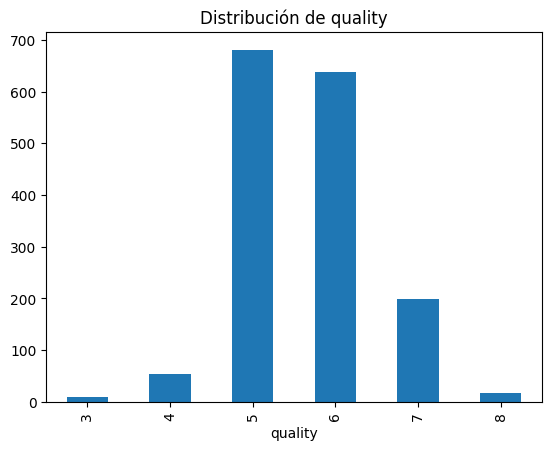

In [0]:
import matplotlib.pyplot as plt
df["quality"].value_counts().sort_index().plot(kind="bar", title="Distribución de quality")
plt.show()

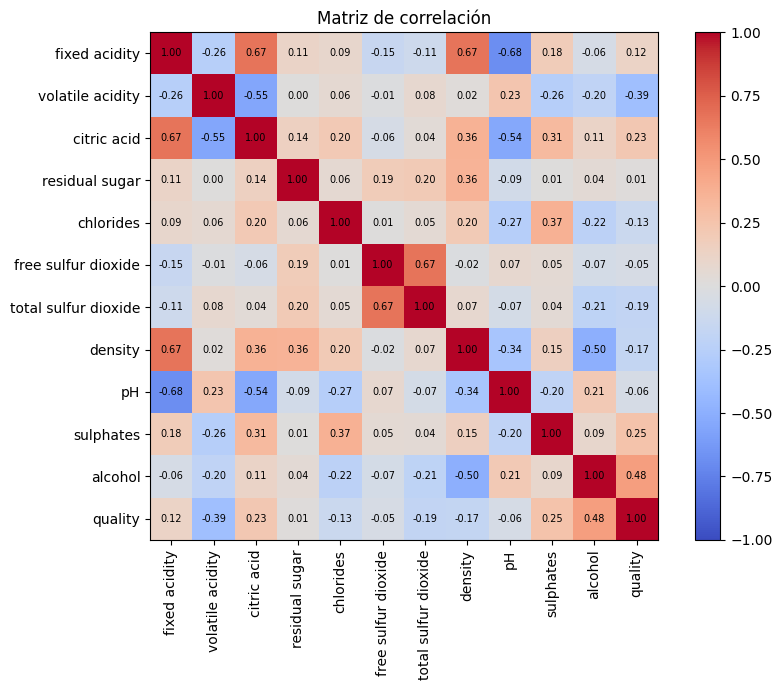

In [0]:
import matplotlib.pyplot as plt
import numpy as np

corr = df.drop(columns="bueno").corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
ax.set_title("Matriz de correlación")
plt.tight_layout()
plt.show()

**Distribución de `quality`:** el gráfico confirma que la calidad se concentra en los puntajes 5 y 6, con una cola hacia 7 y muy pocos vinos en 3, 4 y 8. La forma es aproximadamente simétrica.

**Matriz de correlación:**
- **Relación con `quality`:** se confirma lo visto antes: `alcohol` (0,48) y `volatile acidity` (−0,39) son las más asociadas a la calidad.
- **Correlaciones fuertes entre predictoras:** `fixed acidity` se relaciona con `pH` (−0,68), `citric acid` (0,67) y `density` (0,67); `free sulfur dioxide` y `total sulfur dioxide` correlacionan en 0,67; y hay relaciones moderadas entre `volatile acidity` y `citric acid` (−0,55), `citric acid` y `pH` (−0,54) y `density` y `alcohol` (−0,50).
- **Implicancia para el modelado:** algunas variables aportan información parecida entre sí (por ejemplo, la acidez y el pH). Esto hace más difícil interpretar qué peso tiene cada una en la regresión logística, pero casi no afecta a las predicciones ni a los modelos de árboles. Por eso se conservan todas.

##Paso 6: Partición train/test

Se separa 80% para entrenar y 20% para evaluar. Se usa `stratify=y` para mantener la proporción de vinos buenos en ambos conjuntos y `random_state=42` para que el resultado sea reproducible. Esta misma partición se usa en todos los modelos para que la comparación sea consistente.

In [0]:
from sklearn.model_selection import train_test_split
X = df.drop(columns=["quality", "bueno"]); y = df["bueno"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape, y_train.mean(), y_test.mean())

(1279, 11) (320, 11) 0.5347928068803753 0.534375


El conjunto de entrenamiento tiene 1.279 filas y el de prueba 320, ambos con las 11 variables predictoras. La proporción de vinos buenos es prácticamente idéntica en los dos (53,5 % en train y 53,4 % en test), por lo que la estratificación funcionó. Como se conservaron los duplicados, algunas filas repetidas pueden quedar en ambos conjuntos.